# Stroke-kockázati baseline-modell csoportonkénti vizsgálata

**Kérdés:** eltér-e egy egyszerű, előre rögzített stroke-kockázati modell teljesítménye és kockázatbecslése (1) nőknél és férfiaknál, (2) a 65 év alatti és a legalább 65 éves csoportban?

**Adat:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle, 5110 sor).

**Módszer:**
- 80/20 tanító/teszt szétválasztás (`stratify=stroke`, `random_state=42`), a teszthalmazt egyszer értékelem ki.
- Logisztikus regresszió osztálysúlyozás nélkül (a súlyozás felfelé torzítaná a becsült valószínűségeket, és ez ellehetetlenítené a kalibráció vizsgálatát).
- Egyetlen, minden csoportra közös döntési küszöb: a tanítóadaton, 5-szörös keresztvalidációval kapott valószínűségekből a legmagasabb küszöb, ahol a recall legalább 0,80.
- Csoportonként: téves negatív arány (FNR), téves pozitív arány (FPR), valamint az átlagos becsült kockázat és a tényleges stroke-arány összevetése.

> Oktatási célú elemzés, a modell nem alkalmas klinikai döntéstámogatásra.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
RECALL_TARGET = 0.80

NUM = ["age", "avg_glucose_level", "bmi"]
CAT = ["gender", "hypertension", "heart_disease", "ever_married",
       "work_type", "Residence_type", "smoking_status"]
FEATURES = NUM + CAT

## 1. Adat betöltése

In [ ]:
import kagglehub
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
raw = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])

# Az egyetlen "Other" nemű sort kiszűröm: egy elemből nem lehet csoportot vizsgálni.
df = raw.drop(columns=["id"])
df = df[df["gender"].isin(["Female", "Male"])].reset_index(drop=True)
# Csoportképző változó: csak az audithoz, bemenetként nem használom.
df["age_group"] = np.where(df["age"] >= 65, "≥65", "<65")

print(f"Elemzett sorok: {len(df)}, stroke-arány: {df['stroke'].mean():.2%}")

Elemzett sorok: 5109, stroke-arány: 4.87%


## 2. Feltáró elemzés

Az alaparányok a csoportok között eltérnek. Ez az eredmények értelmezéséhez kell. Modellezési döntés nem épül rá.

In [3]:
rows = []
for col in ["gender", "age_group"]:
    g = df.groupby(col)["stroke"].agg(n="count", stroke="sum")
    g["stroke-arány"] = (g["stroke"] / g["n"]).map("{:.1%}".format)
    rows.append(g)
pd.concat(rows)

,n,stroke,stroke-arány
Female,2994,141,4.7%
Male,2115,108,5.1%
<65,4082,90,2.2%
≥65,1027,159,15.5%


### Életkor és a vizsgált csoportok

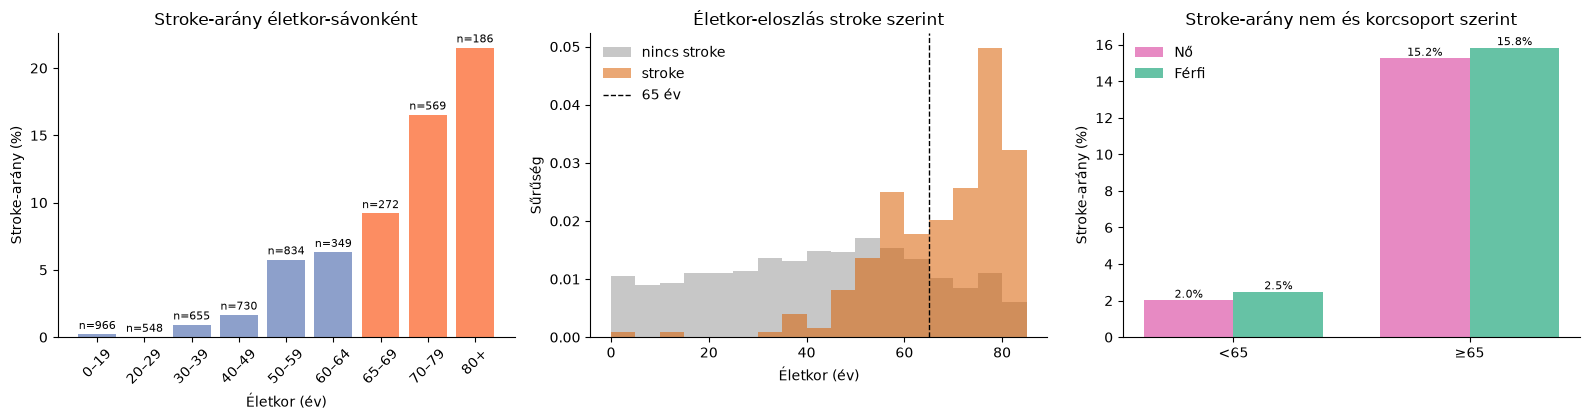

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

# (a) Stroke-arány életkor-sávonként
bands = pd.cut(df["age"], [0, 20, 30, 40, 50, 60, 65, 70, 80, 90], right=False)
by_band = df.groupby(bands, observed=True)["stroke"].agg(n="count", rate="mean")
labels = ["80+" if iv.left == 80 else f"{int(iv.left)}–{int(iv.right) - 1}" for iv in by_band.index]
colors = ["#fc8d62" if iv.left >= 65 else "#8da0cb" for iv in by_band.index]
ax = axes[0]
ax.bar(labels, by_band["rate"] * 100, color=colors)
for i, (r, n) in enumerate(zip(by_band["rate"], by_band["n"])):
    ax.text(i, r * 100 + 0.4, f"n={n}", ha="center", fontsize=8)
ax.set_title("Stroke-arány életkor-sávonként")
ax.set_xlabel("Életkor (év)")
ax.set_ylabel("Stroke-arány (%)")
ax.tick_params(axis="x", rotation=45)

# (b) Életkor-eloszlás stroke szerint
ax = axes[1]
for s, c, lab in [(0, "#999999", "nincs stroke"), (1, "#d95f02", "stroke")]:
    ax.hist(df.loc[df["stroke"] == s, "age"], bins=range(0, 86, 5), density=True,
            alpha=0.55, color=c, label=lab)
ax.axvline(65, color="black", ls="--", lw=1, label="65 év")
ax.set_title("Életkor-eloszlás stroke szerint")
ax.set_xlabel("Életkor (év)")
ax.set_ylabel("Sűrűség")
ax.legend(frameon=False)

# (c) Stroke-arány nem és korcsoport szerint
rate = df.groupby(["age_group", "gender"])["stroke"].mean().unstack().loc[["<65", "≥65"]]
x, w = np.arange(2), 0.38
ax = axes[2]
for dx, col, lab, c in [(-w / 2, "Female", "Nő", "#e78ac3"), (w / 2, "Male", "Férfi", "#66c2a5")]:
    bars = ax.bar(x + dx, rate[col] * 100, w, label=lab, color=c)
    ax.bar_label(bars, fmt="%.1f%%", fontsize=8)
ax.set_xticks(x, ["<65", "≥65"])
ax.set_title("Stroke-arány nem és korcsoport szerint")
ax.set_ylabel("Stroke-arány (%)")
ax.legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Kockázati tényezők és glükózszint

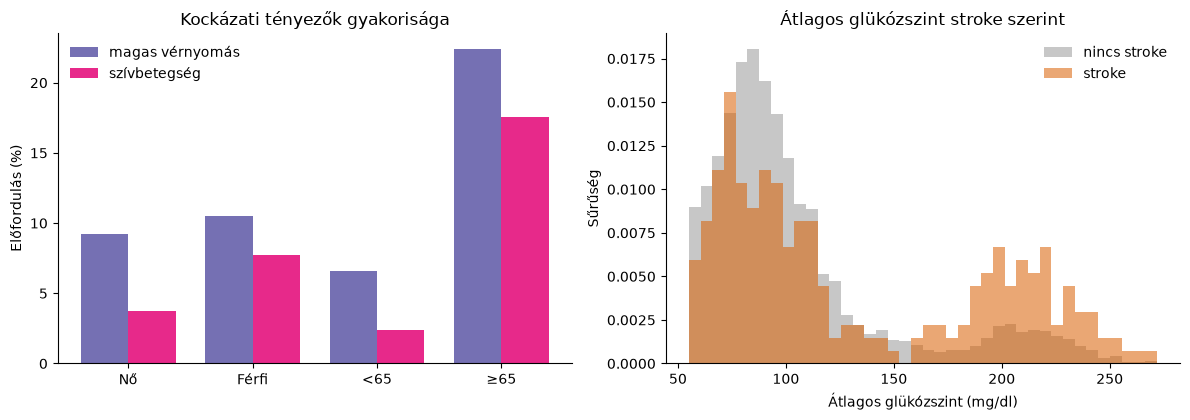

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
grp_order = ["Nő", "Férfi", "<65", "≥65"]

# (a) Kockázati tényezők gyakorisága csoportonként
prev = pd.concat([
    df.groupby("gender")[["hypertension", "heart_disease"]].mean().rename(index={"Female": "Nő", "Male": "Férfi"}),
    df.groupby("age_group")[["hypertension", "heart_disease"]].mean(),
]).loc[grp_order]
x, w = np.arange(len(grp_order)), 0.38
ax = axes[0]
ax.bar(x - w / 2, prev["hypertension"] * 100, w, label="magas vérnyomás", color="#7570b3")
ax.bar(x + w / 2, prev["heart_disease"] * 100, w, label="szívbetegség", color="#e7298a")
ax.set_xticks(x, grp_order)
ax.set_title("Kockázati tényezők gyakorisága")
ax.set_ylabel("Előfordulás (%)")
ax.legend(frameon=False)

# (b) Átlagos glükózszint eloszlása stroke szerint
ax = axes[1]
glu_bins = np.histogram_bin_edges(df["avg_glucose_level"], bins=40)
for s, c, lab in [(0, "#999999", "nincs stroke"), (1, "#d95f02", "stroke")]:
    ax.hist(df.loc[df["stroke"] == s, "avg_glucose_level"], bins=glu_bins, density=True,
            alpha=0.55, color=c, label=lab)
ax.set_title("Átlagos glükózszint stroke szerint")
ax.set_xlabel("Átlagos glükózszint (mg/dl)")
ax.set_ylabel("Sűrűség")
ax.legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Megfigyelések**

- **Az életkor a legerősebb tényező.** A stroke-arány 40 év alatt 0,5% alatti, 50–64 év között ~6%, 70–79 évesen ~17%, 80 felett ~22%. A stroke-esetek 64%-a a 65 év felettiekből kerül ki, holott ők a minta csak 20%-át adják. A stroke-esetek medián életkora 71 év, a többieké 43.
- **A 65 éves határ önkényes.** A kockázat folyamatosan nő, nincs ugrás 65-nél. A két korcsoport ezért belül is heterogén, a ≥65 csoportban a 65 és a 80+ évesek kockázata között több mint kétszeres a különbség.
- **A nemek között korcsoporton belül alig van különbség.** A stroke-arány 65 alatt 2,0% (nő) és 2,5% (férfi), 65 felett 15,2% és 15,8%. A két nem korszerkezete is hasonló (a 65 év felettiek aránya 20,4%, illetve 19,7%). A modell auditjánál tehát a nemek között kis eltérésre számítok.
- **A kockázati tényezők a korcsoportok között sokkal jobban eltérnek, mint a nemek között.** A ≥65 csoportban a magas vérnyomás 22%, a szívbetegség 18% (65 alatt 7%, illetve 2%). Férfiaknál a szívbetegség kétszer olyan gyakori (7,7% kontra 3,8%), a stroke-arány mégis hasonló.
- **A glükózszint eloszlása kétcsúcsú** (egy csúcs 80–95, egy második 200 mg/dl körül). A stroke-esetek 36%-ánál 150 mg/dl feletti az érték, a többieknél csak 13%-nál.
- **Adatminőség:** két stroke-eset 20 év alatti (a legfiatalabb 1,3 éves). Ez orvosilag nem kizárt, de ilyen ritka esetek egy ismeretlen eredetű adathalmazban címkézési hibára is utalhatnak.

## 3. Tanító/teszt szétválasztás

Innentől minden döntés csak a tanítóadatból származik, a teszthalmazhoz az 5. szakaszig nem nyúlok.

In [6]:
train_df, test_df = train_test_split(df, test_size=0.20, random_state=SEED, stratify=df["stroke"])
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

X_train, y_train = train_df[FEATURES], train_df["stroke"].values
X_test, y_test = test_df[FEATURES], test_df["stroke"].values

print(f"Tanító: {len(train_df)} sor ({y_train.sum()} stroke)")
print(f"Teszt:  {len(test_df)} sor ({y_test.sum()} stroke)")

Tanító: 4087 sor (199 stroke)
Teszt:  1022 sor (50 stroke)


## 4. Modell és döntési küszöb (csak a tanítóadaton)

In [7]:
model = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CAT),
    ])),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])

# Keresztvalidált (out-of-fold) valószínűségek: a modell ezeket a sorokat tanuláskor nem látta.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# A legmagasabb küszöb, ahol a recall legalább RECALL_TARGET (pozitív jóslat: p >= küszöb).
fpr, tpr, thr = roc_curve(y_train, oof, drop_intermediate=False)
threshold = float(thr[np.argmax(tpr >= RECALL_TARGET)])
print(f"Rögzített küszöb: {threshold:.4f}")

Rögzített küszöb: 0.0511


## 5. Kiértékelés a teszthalmazon

In [8]:
model.fit(X_train, y_train)
p = model.predict_proba(X_test)[:, 1]
print(f"Teljes teszthalmaz AUC: {roc_auc_score(y_test, p):.3f}")


def group_row(y, p):
    pred = p >= threshold
    pos, neg = (y == 1).sum(), (y == 0).sum()
    tp, fp = (pred & (y == 1)).sum(), (pred & (y == 0)).sum()
    return {
        "n": len(y),
        "stroke-esetek": pos,
        "FNR": (pos - tp) / pos,
        "FPR": fp / neg,
        "precision": tp / (tp + fp) if (tp + fp) else np.nan,
        "átl. becsült kockázat": p.mean(),
        "tényleges arány": y.mean(),
        "becsült − tényleges (pp)": (p.mean() - y.mean()) * 100,
    }


groups = {
    "Összes": np.ones(len(test_df), dtype=bool),
    "Nő": (test_df["gender"] == "Female").values,
    "Férfi": (test_df["gender"] == "Male").values,
    "<65": (test_df["age_group"] == "<65").values,
    "≥65": (test_df["age_group"] == "≥65").values,
}
res = pd.DataFrame({g: group_row(y_test[m], p[m]) for g, m in groups.items()}).T

pct = "{:.1%}"
res.style.format({
    "n": "{:.0f}", "stroke-esetek": "{:.0f}",
    "FNR": pct, "FPR": pct, "precision": pct,
    "átl. becsült kockázat": pct, "tényleges arány": pct,
    "becsült − tényleges (pp)": "{:+.1f}",
})

Teljes teszthalmaz AUC: 0.839


,n,stroke-esetek,FNR,FPR,precision,átl. becsült kockázat,tényleges arány,becsült − tényleges (pp)
Összes,1022,50,18.0%,27.1%,13.5%,5.0%,4.9%,+0.1
Nő,597,29,17.2%,26.2%,13.9%,4.8%,4.9%,-0.0
Férfi,425,21,19.0%,28.2%,13.0%,5.3%,4.9%,+0.4
<65,825,15,60.0%,12.7%,5.5%,2.2%,1.8%,+0.3
≥65,197,35,0.0%,98.8%,17.9%,17.0%,17.8%,-0.8


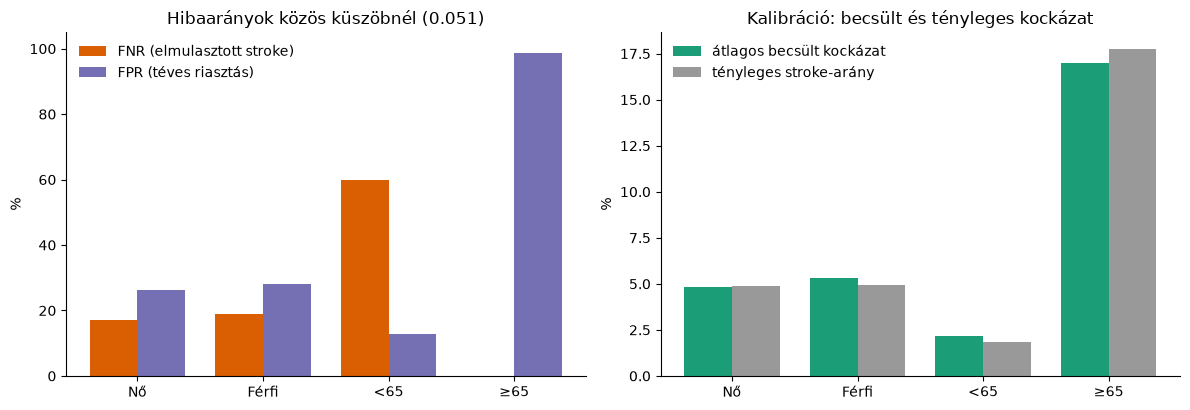

In [9]:
order = ["Nő", "Férfi", "<65", "≥65"]
x = np.arange(len(order))
w = 0.38
sub = res.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.bar(x - w / 2, sub["FNR"] * 100, w, label="FNR (elmulasztott stroke)", color="#d95f02")
ax.bar(x + w / 2, sub["FPR"] * 100, w, label="FPR (téves riasztás)", color="#7570b3")
ax.set_xticks(x, order)
ax.set_ylabel("%")
ax.set_ylim(0, 105)
ax.set_title(f"Hibaarányok közös küszöbnél ({threshold:.3f})")
ax.legend(frameon=False)

ax = axes[1]
ax.bar(x - w / 2, sub["átl. becsült kockázat"] * 100, w, label="átlagos becsült kockázat", color="#1b9e77")
ax.bar(x + w / 2, sub["tényleges arány"] * 100, w, label="tényleges stroke-arány", color="#999999")
ax.set_xticks(x, order)
ax.set_ylabel("%")
ax.set_title("Kalibráció: becsült és tényleges kockázat")
ax.legend(frameon=False)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Eredmények és értelmezés

**Összkép.** A modell a lezárt teszthalmazon AUC = 0,839-et ér el (50 stroke-eset 1022 sorból). A tanítóadaton rögzített küszöb (0,051) mellett a teljes teszthalmazon az FNR 18,0% (a recall 82%, tehát a tanítóadatból célzott 80%-hoz közeli), az FPR 27,1%. Az átlagos becsült kockázat (5,0%) gyakorlatilag megegyezik a tényleges stroke-aránnyal (4,9%), vagyis a modell átlagos szinten jól kalibrált. Az alacsony alaparány miatt a pozitív jóslatok többsége téves riasztás (a precision 13,5%, lásd a táblázatot).

### Nők és férfiak

| | FNR | FPR | becsült kockázat | tényleges arány | különbség |
|---|---|---|---|---|---|
| Nő (29 eset) | 17,2% | 26,2% | 4,8% | 4,9% | −0,0 pp |
| Férfi (21 eset) | 19,0% | 28,2% | 5,3% | 4,9% | +0,4 pp |

A két nem között a különbség kicsi: az FNR különbsége 1,8, az FPR-é 2,0 százalékpont, a kalibrációs eltérés pedig mindkét csoportban 0,5 pp alatt van. A teszthalmazban a két nemnél azonos a tényleges stroke-arány (4,9%), így közös küszöbnél hasonló hibaarányokat is várok. A nemek közt tehát nem látszik érdemi eltérés. Ezt óvatosan kell kimondani: az FNR 29, illetve 21 esetre épül, és egyetlen eset átbillenése 3,4, illetve 4,8 százalékpontot mozgat rajta, ezért az 1,8 pp-os különbség a zajon belül van. A „nincs bizonyított különbség" nem azonos azzal, hogy „biztosan nincs különbség".

### 65 év alattiak és legalább 65 évesek

| | FNR | FPR | becsült kockázat | tényleges arány | különbség |
|---|---|---|---|---|---|
| <65 (15 eset) | 60,0% | 12,7% | 2,2% | 1,8% | +0,3 pp |
| ≥65 (35 eset) | 0,0% | 98,8% | 17,0% | 17,8% | −0,8 pp |

Itt a két csoport közötti különbség drámai, és ezt az alaparányok közti óriási eltérés magyarázza (a teljes adathalmazon 2,2% a <65 és 15,5% a ≥65 csoportban, a teszthalmazban 1,8% és 17,8%).

- **≥65:** a küszöb (5,1%) jóval a csoport átlagos becsült kockázata (17,0%) alatt van, ezért a modell gyakorlatilag mindenkit pozitívnak jelöl (FPR 98,8%). Az FNR = 0% itt nem a modell erőssége, hanem a küszöb következménye: a közös küszöb ebben a csoportban nem szelektál.
- **<65:** a modell az esetek 60%-át elmulasztja (15-ből 9-et), miközben a téves pozitívak aránya alacsony (12,7%). Ez a modell legsúlyosabb gyengesége: a fiatalabb betegek stroke-jainak többségét nem ismeri fel.
- **Kalibráció:** az átlagos becsült kockázat mindkét korcsoportban közel van a tényleges arányhoz (+0,3 és −0,8 pp), tehát a kockázatbecslés átlagos szinten mindkét csoportban helytálló. A hibaarányok eltérése így nem rossz kalibrációból, hanem a közös küszöb és a különböző alaparányok kölcsönhatásából jön. Ez megfelel annak az elméleti eredménynek, hogy eltérő alaparányú csoportokban a kalibráció és az egyenlő hibaarányok általában nem teljesülhetnek egyszerre (Kleinberg és mtsai, 2016; Chouldechova, 2017).

### Válasz a kérdésre

1. **Nem szerint** nem találtam érdemi eltérést sem a hibaarányokban, sem a kalibrációban. A kis esetszám miatt ez inkább „nincs kimutatott eltérés", mint bizonyított egyenlőség.
2. **Életkor szerint** a hibaarányok erősen eltérnek (FNR 60% kontra 0%, FPR 12,7% kontra 98,8%), a kockázatbecslés átlagos kalibrációja viszont mindkét csoportban jó. A különbség fő oka az alaparány, de a következmény gyakorlati: a közös küszöb a fiatalabbaknál sok esetet elmulaszt, az időseknél pedig mindenkit jelöl, így ott a modell nem ad használható szűrést.

Ha a gyakorlatban a <65 csoport FNR-je számítana, csoportonkénti küszöb vagy külön modell lehetne megoldás. Ez kívül esik a feladat keretein, mert egyetlen közös küszöböt használok.

### Korlátok
- **Kevés stroke-eset**, különösen a 65 év alattiaknál (15): az ottani FNR (60%) néhány esetre épül, ezért nagyon bizonytalan. Konfidenciaintervallumot nem számoltam, ezért a csoportok közti különbségekről nem tudom kimondani, hogy statisztikailag megalapozottak. Az életkor szerinti különbség azonban olyan nagy (9 kontra 0 elmulasztott eset), hogy iránya szinte biztosan nem véletlen, formális tesztet viszont nem végeztem.
- **Az átlagos kalibráció nem teljes kalibráció.** Csak a csoportátlagot vetettem össze, azt nem vizsgáltam, hogy a csoportokon belül a magasabb becsült kockázat a tényleges magasabb arányt jelzi-e. Ehhez csoportonkénti AUC vagy kalibrációs görbe kellene.
- **Egyetlen szétválasztás**, más véletlen felosztással az értékek elmozdulhatnak.
- **A küszöb egy önkényes célból jön** (recall ≥ 0,80), más célnál a hibaarányok is mások lennének.
- Az adathalmaz eredete ismeretlen, a modell keresztmetszeti adatból a meglévő stroke-státuszt becsüli, nem előrejelez klinikai értelemben.
- A BMI hiányzó értékeit mediánnal pótoltam.
- Az eredmények oktatási célúak, a modell nem alkalmas klinikai döntéstámogatásra.